# Practice MIT Linear Alegbra
# Predicting F1 Lap Times using Linear Algebra Regression - 

In [19]:
import numpy as np
from numpy import linalg as lng
import matplotlib.pyplot as plt

In [20]:
# Synthetic F1 practice data
fuel_load = np.array([100, 90, 80, 70, 60, 50], dtype=float)

lap_time = np.array([92.5, 91.8, 91.2, 90.1, 89.7, 88.9], dtype=float)

print("Fuel Load: ", fuel_load)
print("Lap Time: ", lap_time)
print("Fuel Load shape: ", fuel_load.shape)
print("Lap Time shape: ", lap_time.shape)

Fuel Load:  [100.  90.  80.  70.  60.  50.]
Lap Time:  [92.5 91.8 91.2 90.1 89.7 88.9]
Fuel Load shape:  (6,)
Lap Time shape:  (6,)


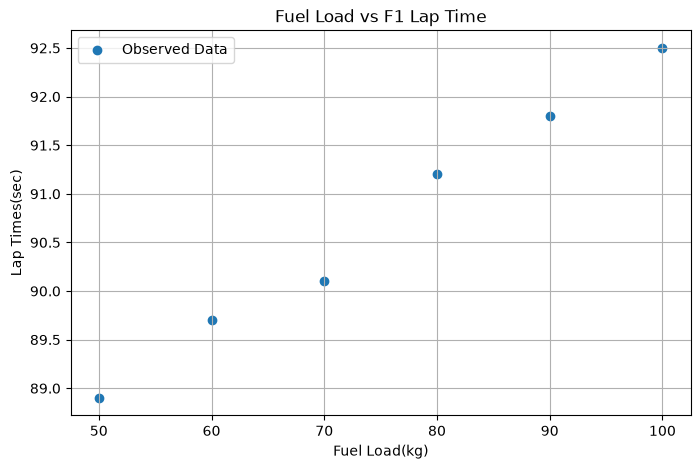

In [5]:
plt.figure(figsize=(8,5))

plt.scatter(fuel_load, lap_time, label="Observed Data")

plt.title("Fuel Load vs F1 Lap Time")
plt.xlabel("Fuel Load(kg)")
plt.ylabel("Lap Times(sec)")


plt.legend()
plt.grid(True)

plt.show()


In [ ]:
# Build the design Matrix
A = np.column_stack((np.ones(len(fuel_load)), fuel_load))

b = lap_time

weights, residual, rank, singular_values = np.linalg.lstsq (
    A, b, rcond=None
)

print("Weights(intercept, slope): ", weights)


Weights(intercept, slope):  [8.52571429e+01 7.25714286e-02]


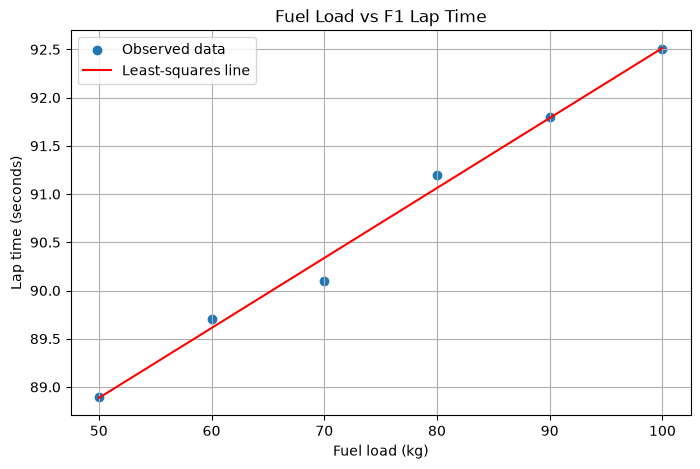

In [14]:
# Predicted lap times
predicted = A @ weights

plt.figure(figsize=(8, 5))

plt.scatter(fuel_load, lap_time, label="Observed data")

# Plot the fitted line
plt.plot(fuel_load, predicted, color="red", label="Least-squares line")

plt.xlabel("Fuel load (kg)")
plt.ylabel("Lap time (seconds)")
plt.title("Fuel Load vs F1 Lap Time")
plt.legend()
plt.grid(True)
plt.show()

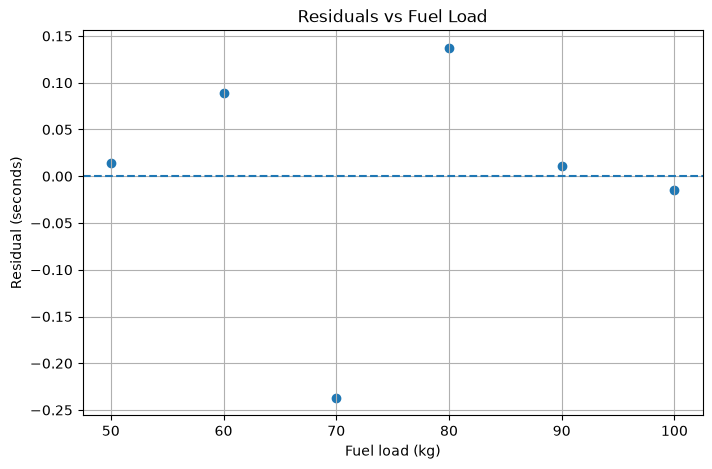

In [17]:
# Calculate residuals
errors = lap_time - predicted

plt.figure(figsize=(8, 5))

plt.scatter(fuel_load, errors)

# Add a horizontal line at zero error
plt.axhline(y=0, linestyle="--")

plt.xlabel("Fuel load (kg)")
plt.ylabel("Residual (seconds)")
plt.title("Residuals vs Fuel Load")
plt.grid(True)

plt.show()

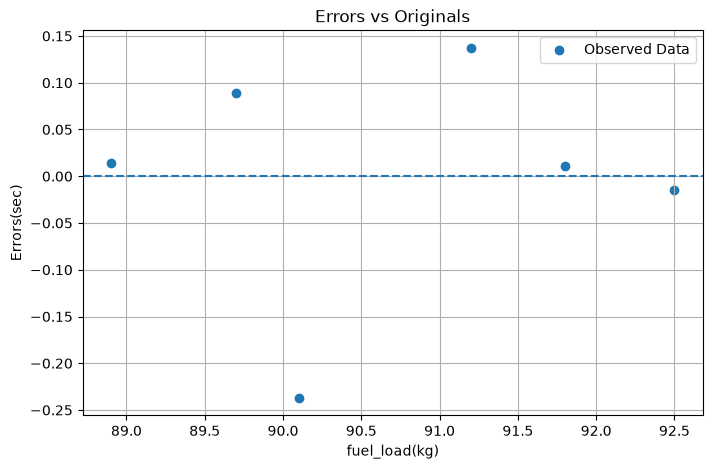

In [33]:
errors = lap_time - predicted

plt.figure(figsize=(8,5))

plt.scatter(lap_time, errors, label="Observed Data")

plt.axhline(y=0, linestyle="--")

plt.title("Errors vs Originals")
plt.xlabel("fuel_load(kg)")
plt.ylabel("Errors(sec)")

plt.grid(True)
plt.legend()

plt.show()



In [34]:
SSE = np.sum(errors ** 2)

RMSE = np.sqrt(np.mean(errors ** 2))

print("SSE: ", SSE)
print("RMSE: ", RMSE)

SSE:  0.0834285714285751
RMSE:  0.11791845447071682


In [35]:
# Calculate the mean of actual lap times

mean_lap_time = np.mean(lap_time)

SST = np.sum((lap_time - mean_lap_time) ** 2)

R_squared = 1 - (SSE / SST)

print("SST: ", SST)
print("R squared: ", R_squared)
print("Variation Explained: ", R_squared * 100, " %")

SST:  9.299999999999976
R squared:  0.9910291858678951
Variation Explained:  99.10291858678951  %


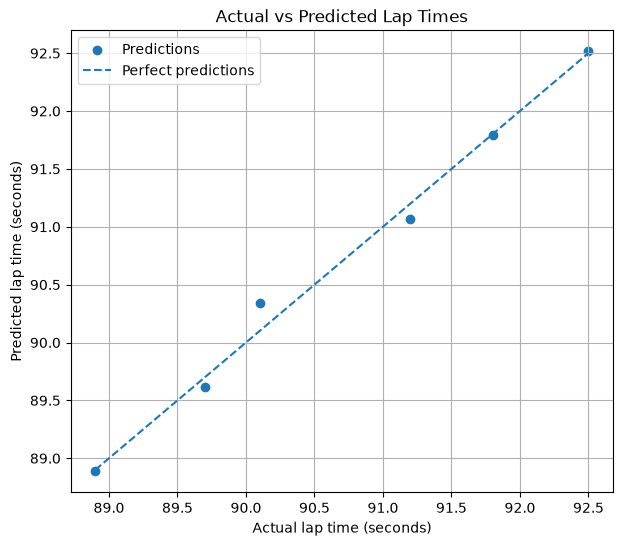

In [36]:
plt.figure(figsize=(7, 6))

plt.scatter(lap_time, predicted, label="Predictions")

# Perfect prediction reference line
plt.plot(
    [lap_time.min(), lap_time.max()],
    [lap_time.min(), lap_time.max()],
    linestyle="--",
    label="Perfect predictions"
)

plt.xlabel("Actual lap time (seconds)")
plt.ylabel("Predicted lap time (seconds)")
plt.title("Actual vs Predicted Lap Times")
plt.legend()
plt.grid(True)
plt.show()